# Importación de librerias

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

sns.set_theme(style="whitegrid")

# Carga de datos
El primero paso será importar el archivo y visualizar las primeras filas del dataset para ver que estructura tiene. 

In [ ]:
data = pd.read_csv('/workspace/dataset.csv')

display(data.head())

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


# Preprocesamiento de datos
Verificamos si existen valores nulos o incosistencias.

In [3]:
print("Valores nulos por columna:")
print(data.isnull().sum())

Valores nulos por columna:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64


No existen pues por lo tanto no hace falta imputar valores. Procedemos al escalado de datos. 

In [5]:
features = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
X = data[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=features)

# Algoritmo KMeans
Primero definimos el número de clusters a formar. El valor óptimo lo vamos a buscar mediante el método del codo. 

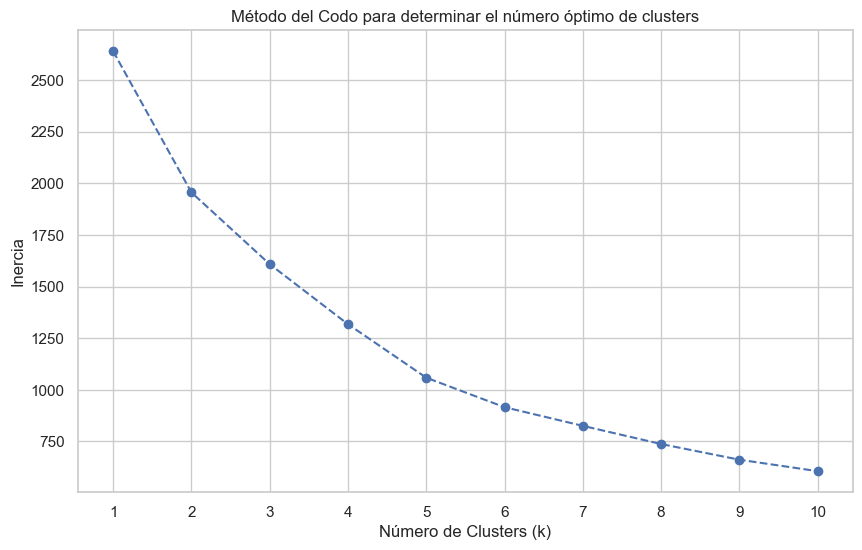

In [6]:
inercia = []
rango_k = range(1, 11)

for k in rango_k:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled_df)
    inercia.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(rango_k, inercia, marker='o', linestyle='--')
plt.title('Método del Codo para determinar el número óptimo de clusters')
plt.xlabel('Número de Clusters (k)')
plt.ylabel('Inercia')
plt.xticks(rango_k)
plt.show()

Como podemos ver el valor donde la inercia deja de disminuir de manera drástica es cuando k = 5. Por lo tanto, este es el valor óptimo. Ahora podemos aplicar el algoritmo. 

In [7]:
k_optimo = 5
kmeans_final = KMeans(n_clusters=k_optimo, init='k-means++', random_state=42, n_init=10)
data['Cluster'] = kmeans_final.fit_predict(X_scaled_df)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled_df)

data['PCA1'] = X_pca[:, 0]
data['PCA2'] = X_pca[:, 1] 


# Visualización de resultados
Por último vamos a generar gráficos para visualizar los clusters:

- Gráfico de Clusters en 2D utilizando PCA
- Método del codo
- Boxplots por cluster

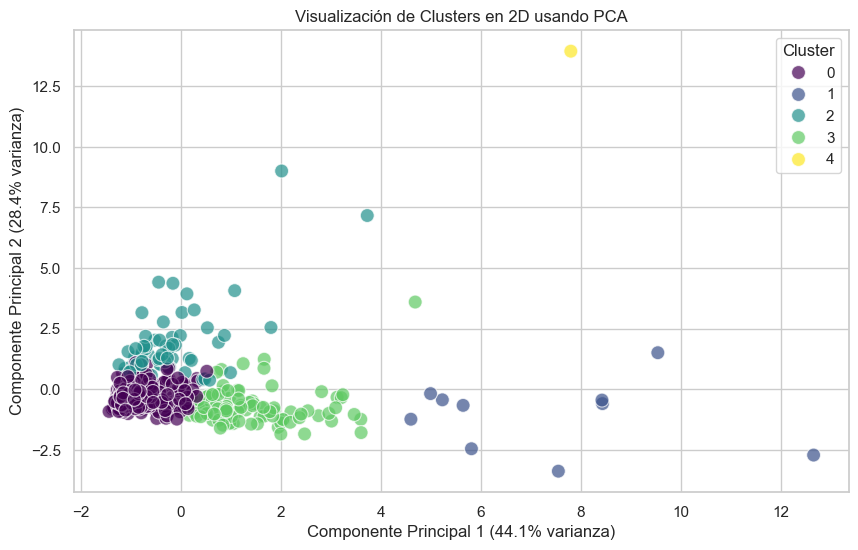

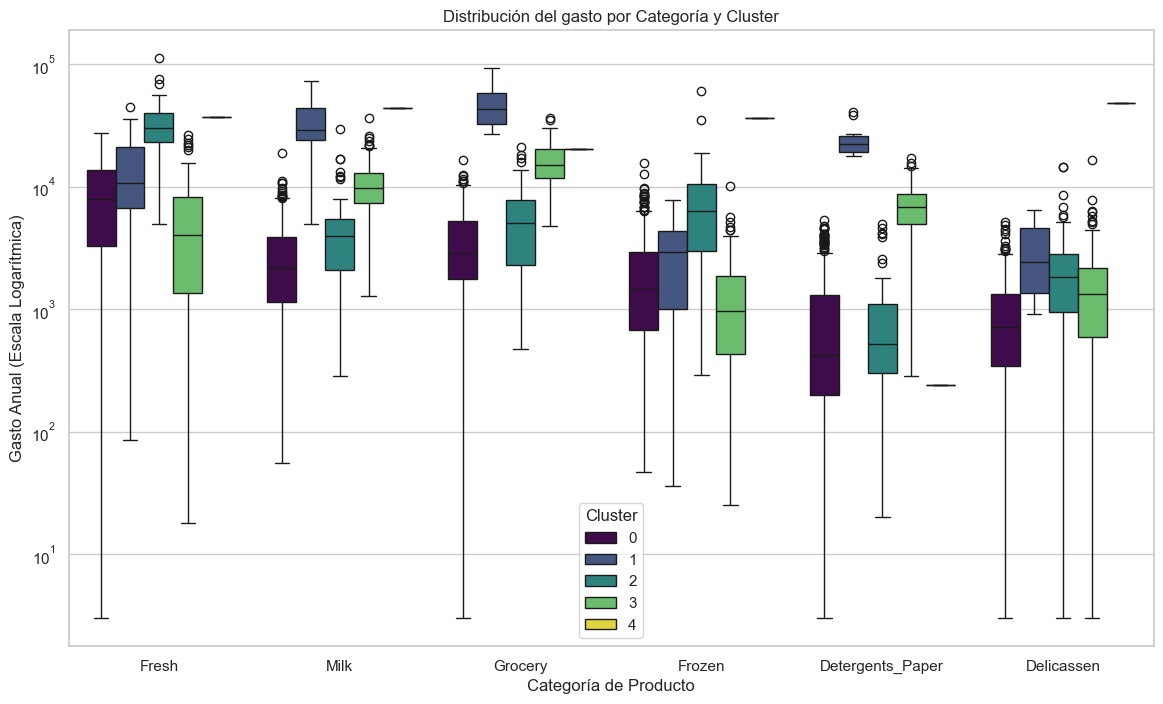

Promedio de gasto por categoría para cada cluster:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,9092.155556,2967.759259,3807.411111,2271.759259,989.814815,978.962963
1,15964.900000,34708.500000,48536.900000,3054.600000,24875.200000,2942.800000
2,32957.984127,4997.349206,5884.761905,8422.841270,954.603175,2462.968254
3,5754.166667,10866.604167,16607.104167,1464.125000,7202.875000,1813.385417
4,36847.000000,43950.000000,20170.000000,36534.000000,239.000000,47943.000000


In [8]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1], 
    hue=data['Cluster'], 
    palette='viridis', 
    s=100, alpha=0.7
)
plt.title('Visualización de Clusters en 2D usando PCA')
plt.xlabel(f'Componente Principal 1 ({pca.explained_variance_ratio_[0]*100:.1f}% varianza)')
plt.ylabel(f'Componente Principal 2 ({pca.explained_variance_ratio_[1]*100:.1f}% varianza)')
plt.legend(title='Cluster')
plt.show()


data_melted = pd.melt(
    data, 
    id_vars=['Cluster'], 
    value_vars=features, 
    var_name='Categoría de Producto', 
    value_name='Gasto Anual'
)

plt.figure(figsize=(14, 8))
sns.boxplot(x='Categoría de Producto', y='Gasto Anual', hue='Cluster', data=data_melted, palette='viridis')
plt.title('Distribución del gasto por Categoría y Cluster')
plt.yscale('log') 
plt.ylabel('Gasto Anual (Escala Logarítmica)')
plt.show()

promedios_cluster = data.groupby('Cluster')[features].mean()
print("Promedio de gasto por categoría para cada cluster:")
display(promedios_cluster)